<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · Build the current file inventory

**Which files exceed our size threshold after a delta update?** Start with a full
inventory, apply renamed/resized files, an addition and a removal, then measure
the large-file footprint. The known-size total happens to stay unchanged in this
synthetic example, so checking only that total would miss an incorrect inventory.

**Synthetic local HTTP data, real worker functions.** All names, sizes, IDs and
June 2026 timestamps are invented. The unchanged v0.4.0 functions page and decode
the responses through VGI. Their existing client-factory seam points to a loopback
fixture, with authentication outside the example's scope. No real account calls,
file downloads, content inspection or remote changes occur.

## Choose the size threshold

`LARGE_FILE_MIB` is an integer from **1 through 64**, inclusive. The comparison is
**size ≥ threshold**; **1 MiB = 1,048,576 bytes**. The default is **8 MiB** and the
experiment raises it to **16 MiB**. This changes the final selection, not the
retrieved change feed. Restart the kernel and run all after editing.

All fixture objects are files. One has unknown size and one has a measured size
of zero. Unknown size stays NULL and is excluded from byte totals; zero stays a
valid measurement. These are logical item sizes, not billed storage or network traffic.

In [1]:
LARGE_FILE_MIB = 8  # inclusive threshold in MiB; integer from 1 through 64

In [2]:
import os
import sys
from pathlib import Path
from tempfile import TemporaryDirectory

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "notebook_support.py").is_file() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR))
os.chdir(NOTEBOOK_DIR)
import haybarn
import matplotlib.pyplot as plt
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme

fixture, previous_url = configure(LARGE_FILE_MIB)
theme()
fixture_secret_directory = TemporaryDirectory(prefix="vgi-fixture-secrets-")
con = haybarn.connect(
    config={"secret_directory": fixture_secret_directory.name, "allow_persistent_secrets": False}
)
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == [], (
    "Fixture must start without SQL secrets"
)
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-files/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-files/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-files/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-files/notebooks/pyproject.toml.

## Connect the release and its fixture transport

The native **v0.4.0** connection supplies credential-free collection discovery.
The Bun/Git launcher pins the exact same release source revision,
**`4162efcdf50bd041b5baaa87faf41d895556b49c`**, and installs its frozen lock in an
ignored local cache. It registers the unchanged exported functions and catalog;
only their injected client sends GET requests to the synthetic loopback server.
Git, Bun and initial downloads are needed, with no parent worker checkout.

The secret below contains public dummy strings. It satisfies the function's secret
lookup but does not authenticate with Microsoft Entra. The fixture rejects
unsupported endpoints and never forwards requests. Download URLs remain disabled.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'azure' AS azure_release (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-azure-files@v0.4.0');
-- The launcher pins remote source 4162efcdf50bd041b5baaa87faf41d895556b49c (v0.4.0).
ATTACH 'azure' AS azure_fixture (TYPE vgi, LOCATION 'bash launch_fixture.sh');
CREATE TEMPORARY SECRET notebook_fixture (TYPE azure_graph,
    TENANT_ID '00000000-0000-0000-0000-000000000001',
    CLIENT_ID '00000000-0000-0000-0000-000000000002',
    CLIENT_SECRET 'synthetic-not-a-credential');
SELECT * FROM azure_release.main.content_collections;

,collection,resource,table_function,description
0,drive_items,driveItem,drive_items,OneDrive / SharePoint document-library files a...
1,list_items,listItem,sharepoint_list_items,SharePoint list items (with user-defined colum...


In [4]:
fixture_secrets = con.execute(
    "SELECT name, persistent, storage FROM duckdb_secrets() ORDER BY name"
).fetchall()
assert fixture_secrets == [("notebook_fixture", False, "memory")], (
    "Only the public temporary fixture secrets may exist"
)

In [5]:
prose(
    f"**Local synthetic Graph fixture:** `{fixture.url}`. Analytical scans use "
    "`azure_fixture.main.drive_items`; native release discovery uses `azure_release`. "
    "All fixture requests are read-only metadata GETs."
)

**Local synthetic Graph fixture:** `http://127.0.0.1:58307`. Analytical scans use `azure_fixture.main.drive_items`; native release discovery uses `azure_release`. All fixture requests are read-only metadata GETs.

## Materialize the full scan before saving its cursor

A scan returns business rows and one final marker. The marker's `_delta_next` is
an opaque per-drive deltaLink, available only after pagination completes. Preserve
it verbatim for that drive. It is not a file or a global cursor for all resources.
Each API call is materialized once; DataFrame captures below read local tables.

In [6]:
%%sql
CREATE TABLE initial_batch AS
SELECT * FROM azure_fixture.main.drive_items('notebook-drive', page_size := 3);
CREATE TABLE inventory_before AS
SELECT 'notebook-drive' AS drive_id, id, name, size, web_url, last_modified_date_time
FROM initial_batch WHERE _row_kind IS NULL AND change_type = 'upsert';
CREATE TABLE inventory AS SELECT * FROM inventory_before;
CREATE TABLE sync_state AS
SELECT 'notebook-drive' AS drive_id, _delta_next AS delta_next
FROM initial_batch WHERE _row_kind = 'marker';
SELECT count(*) AS items, count(size) AS known_sizes,
       count(*) FILTER (WHERE size IS NULL) AS unknown_sizes,
       count(*) FILTER (WHERE size = 0) AS measured_zero_sizes,
       sum(size) / 1048576.0 AS known_mib FROM inventory;

,items,known_sizes,unknown_sizes,measured_zero_sizes,known_mib
0,8,7,1,1,78.5


In [7]:
%%sql cursor_row <<
SELECT * FROM sync_state;

In [8]:
display(cursor_row)
assert len(cursor_row) == 1 and cursor_row.iloc[0].drive_id == "notebook-drive"
delta_token = cursor_row.iloc[0].delta_next
# SQL quoting preserves the opaque link; do not rebuild or edit its query parameters.
delta_token_sql = "'" + delta_token.replace("'", "''") + "'"
prose(
    "The stored synthetic cursor is scoped to `notebook-drive`. The next call "
    "replays this exact link, including its encoded opaque parameter."
)

,drive_id,delta_next
0,notebook-drive,https://graph.microsoft.com/v1.0/drives/notebo...


The stored synthetic cursor is scoped to `notebook-drive`. The next call replays this exact link, including its encoded opaque parameter.

## Read the delta as changes, not a new full snapshot

The fixture publishes a later snapshot with two updated files, one addition and
one removal. Removed rows contain the ID and reason, with NULL business metadata.
They are deletion instructions for the local inventory, not zero-byte files.
This Python setup changes only the local fixture snapshot.

In [9]:
fixture.publish_changes()

In [10]:
%%sql
CREATE TABLE changes_batch AS
SELECT * FROM azure_fixture.main.drive_items('notebook-drive', delta_token := {{delta_token_sql}});
SELECT id, change_type, removed_reason, name, size
FROM changes_batch WHERE _row_kind IS NULL ORDER BY id;

,id,change_type,removed_reason,name,size
0,b,upsert,None,simulation-final.bin,41943040
1,c,upsert,None,briefing-v2.pptx,6291456
2,d,removed,deleted,None,<NA>
3,i,upsert,None,recording.wav,18874368


In [11]:
%%sql batch_check <<
SELECT count(*) = count(DISTINCT id) AND bool_and(id IS NOT NULL AND id <> '') AS unique_change_ids,
       bool_and(change_type IN ('upsert', 'removed')) AS known_operations,
       (SELECT count(*) FROM changes_batch WHERE _row_kind = 'marker') = 1 AS one_marker
FROM changes_batch WHERE _row_kind IS NULL;

In [12]:
display(batch_check)
assert batch_check.notna().all().all() and batch_check.all().all(), "Ambiguous change batch"
prose(
    "This simple SQL merge requires one change per item ID in the batch; the check "
    "stops on duplicate IDs instead of selecting an arbitrary version. The marker is kept separate."
)

,unique_change_ids,known_operations,one_marker
0,True,True,True


This simple SQL merge requires one change per item ID in the batch; the check stops on duplicate IDs instead of selecting an arbitrary version. The marker is kept separate.

## Replace changed IDs and remove tombstones

Delete existing rows for every changed ID, then insert only upserts. Scope the
operation to the drive. Advance that drive's cursor after applying its changes.
The tables here are in memory: a production sink must commit inventory changes
and the corresponding cursor atomically on one transactional connection.

For validation, make one explicit fresh full scan of the revised fixture. A
normal incremental consumer would not need this additional reference request.

In [13]:
%%sql
DELETE FROM inventory WHERE drive_id = 'notebook-drive'
  AND id IN (SELECT id FROM changes_batch WHERE _row_kind IS NULL);
INSERT INTO inventory
SELECT 'notebook-drive', id, name, size, web_url, last_modified_date_time
FROM changes_batch WHERE _row_kind IS NULL AND change_type = 'upsert';
UPDATE sync_state SET delta_next =
    (SELECT _delta_next FROM changes_batch WHERE _row_kind = 'marker')
WHERE drive_id = 'notebook-drive';
CREATE TABLE fresh_inventory AS
SELECT 'notebook-drive' AS drive_id, id, name, size, web_url, last_modified_date_time
FROM azure_fixture.main.drive_items('notebook-drive', page_size := 3)
WHERE _row_kind IS NULL AND change_type = 'upsert';
CREATE TABLE event_log AS
SELECT id, size FROM initial_batch WHERE _row_kind IS NULL
UNION ALL SELECT id, size FROM changes_batch WHERE _row_kind IS NULL;
SELECT 'Append-only event log' AS representation, count(*) AS rows, sum(size)/1048576.0 AS known_mib FROM event_log
UNION ALL SELECT 'Current inventory', count(*), sum(size)/1048576.0 FROM inventory
UNION ALL SELECT 'Fresh full-scan reference', count(*), sum(size)/1048576.0 FROM fresh_inventory;

,representation,rows,known_mib
0,Append-only event log,12,142.5
1,Current inventory,8,78.5
2,Fresh full-scan reference,8,78.5


In [14]:
%%sql coverage <<
SELECT count(*) AS items, count(size) AS known_sizes,
       count(*) FILTER (WHERE size IS NULL) AS unknown_sizes,
       count(*) FILTER (WHERE size = 0) AS measured_zero_sizes,
       sum(size) / 1048576.0 AS known_mib,
       (sum(size) - (SELECT sum(size) FROM inventory_before)) / 1048576.0 AS net_change_mib,
       (SELECT count(*) FROM event_log) AS event_rows,
       (SELECT sum(size) / 1048576.0 FROM event_log) AS event_sum_mib
FROM inventory;

In [15]:
a = coverage.iloc[0]
prose(
    f"The current inventory contains **{int(a['items'])} items** and **{a.known_mib:.1f} MiB** "
    f"of known sizes: **{int(a.unknown_sizes)} unknown** and **{int(a.measured_zero_sizes)} measured zero** "
    f"remain distinct. Known size changed by **{a.net_change_mib:+.1f} MiB**, even though items changed. "
    f"The append-only event log has **{int(a.event_rows)} rows** and sums to **{a.event_sum_mib:.1f} MiB**; "
    "those versions and removals are useful history, not the current storage footprint."
)

The current inventory contains **8 items** and **78.5 MiB** of known sizes: **1 unknown** and **1 measured zero** remain distinct. Known size changed by **+0.0 MiB**, even though items changed. The append-only event log has **12 rows** and sums to **142.5 MiB**; those versions and removals are useful history, not the current storage footprint.

## Explain the net size change

Join the before and after inventories by drive and ID. An added or removed item
contributes its known size with the appropriate sign. Unknown sizes remain NULL;
the chart shows only measurable changes. These metadata differences do not measure
transferred bytes or physical storage reclamation.

In [16]:
%%sql size_changes <<
SELECT coalesce(n.name, b.name) AS name,
       CASE WHEN b.id IS NULL THEN 'Added' WHEN n.id IS NULL THEN 'Removed' ELSE 'Updated' END AS action,
       CASE WHEN b.id IS NULL THEN n.size WHEN n.id IS NULL THEN -b.size ELSE n.size - b.size END
           / 1048576.0 AS size_change_mib
FROM inventory_before b FULL JOIN inventory n ON b.drive_id = n.drive_id AND b.id = n.id
WHERE coalesce(b.id,n.id) IN (SELECT id FROM changes_batch WHERE _row_kind IS NULL)
ORDER BY size_change_mib, name;

findfont: Failed to find font weight semibold for Arial, now using 700.


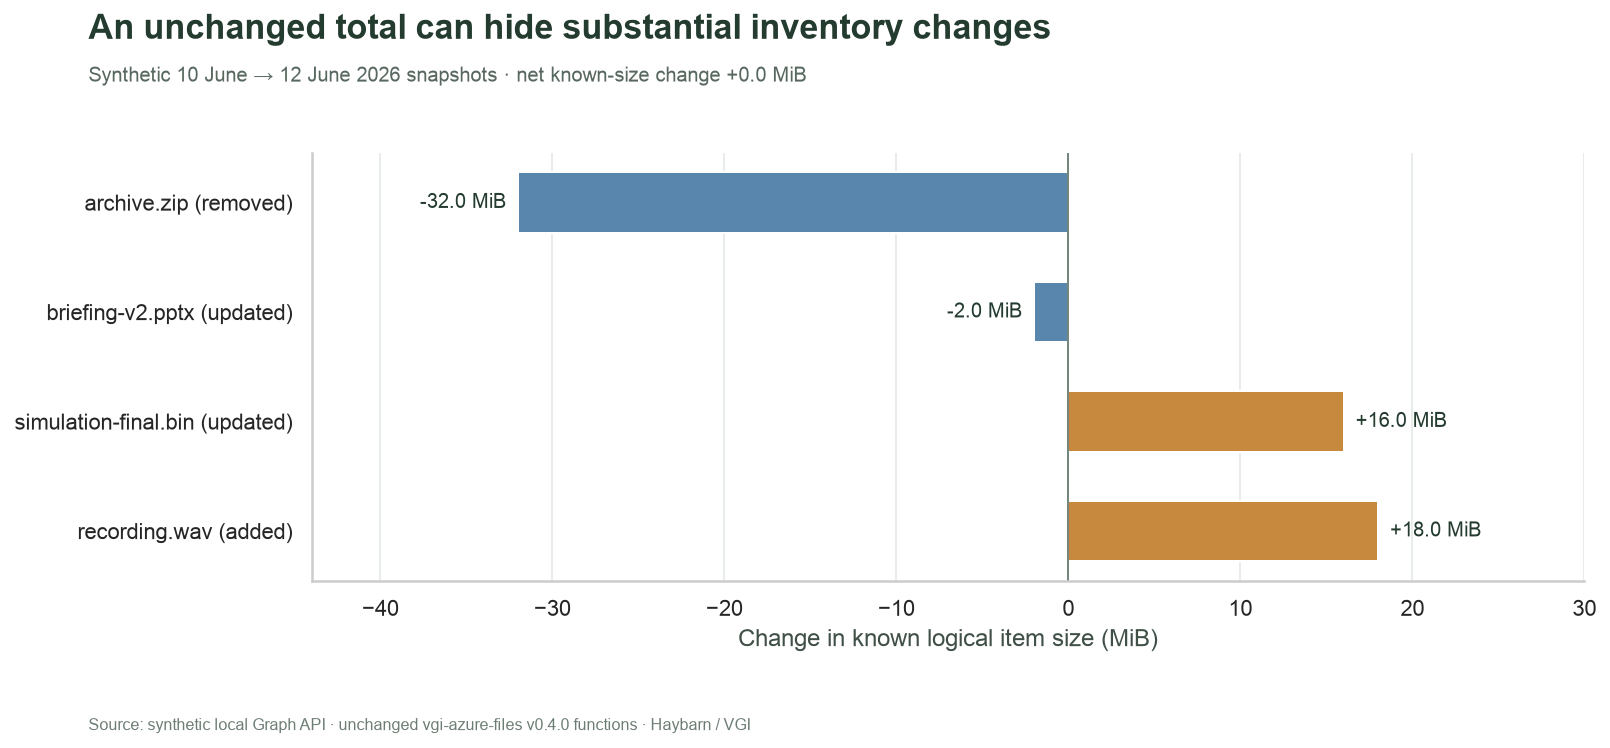

In [17]:
plot_changes = size_changes.loc[size_changes.size_change_mib.notna()]
fig, ax = plt.subplots(figsize=(11.5, 5.2))
colors = ["#C7893D" if x > 0 else "#5986AD" for x in plot_changes.size_change_mib]
labels = [f"{row['name']} ({row['action'].lower()})" for _, row in plot_changes.iterrows()]
bars = ax.barh(labels, plot_changes.size_change_mib, color=colors, height=0.55)
ax.bar_label(bars, labels=[f"{v:+.1f} MiB" for v in plot_changes.size_change_mib], padding=6, fontsize=10)
ax.axvline(0, color="#75867C", linewidth=1)
ax.set_xlim(min(0, plot_changes.size_change_mib.min()) - 12, max(0, plot_changes.size_change_mib.max()) + 12)
ax.invert_yaxis()
ax.set_xlabel("Change in known logical item size (MiB)")
ax.grid(axis="y", visible=False)
chart(
    fig,
    "An unchanged total can hide substantial inventory changes",
    f"Synthetic 10 June → 12 June 2026 snapshots · net known-size change {a.net_change_mib:+.1f} MiB",
)

## Measure the current large-file footprint

Apply the threshold to the corrected inventory. Use the known-size total as the
percentage denominator and report unknown-size coverage alongside it. The result
is an inventory selection, not a recommendation to delete files: no ownership,
retention requirements or content were evaluated.

In [18]:
%%sql current_sizes <<
SELECT id, name, size / 1048576.0 AS size_mib, size >= {{LARGE_FILE_MIB}} * 1048576 AS selected
FROM inventory WHERE size IS NOT NULL ORDER BY size DESC, id;

In [19]:
%%sql selection <<
SELECT count(*) FILTER (WHERE size >= {{LARGE_FILE_MIB}} * 1048576) AS selected_items,
       coalesce(sum(size) FILTER (WHERE size >= {{LARGE_FILE_MIB}} * 1048576),0) / 1048576.0 AS selected_mib,
       100.0 * coalesce(sum(size) FILTER (WHERE size >= {{LARGE_FILE_MIB}} * 1048576),0)
           / nullif(sum(size),0) AS share_known_pct
FROM inventory;

In [20]:
s = selection.iloc[0]
prose(
    f"At **{LARGE_FILE_MIB} MiB or larger**, **{int(s.selected_items)} items** account for "
    f"**{s.selected_mib:.1f} MiB**, or **{s.share_known_pct:.2f}%** of known-size bytes. "
    f"The **{int(a.unknown_sizes)} unknown-size item(s)** cannot be classified by this threshold."
)

At **8 MiB or larger**, **3 items** account for **70.0 MiB**, or **89.17%** of known-size bytes. The **1 unknown-size item(s)** cannot be classified by this threshold.

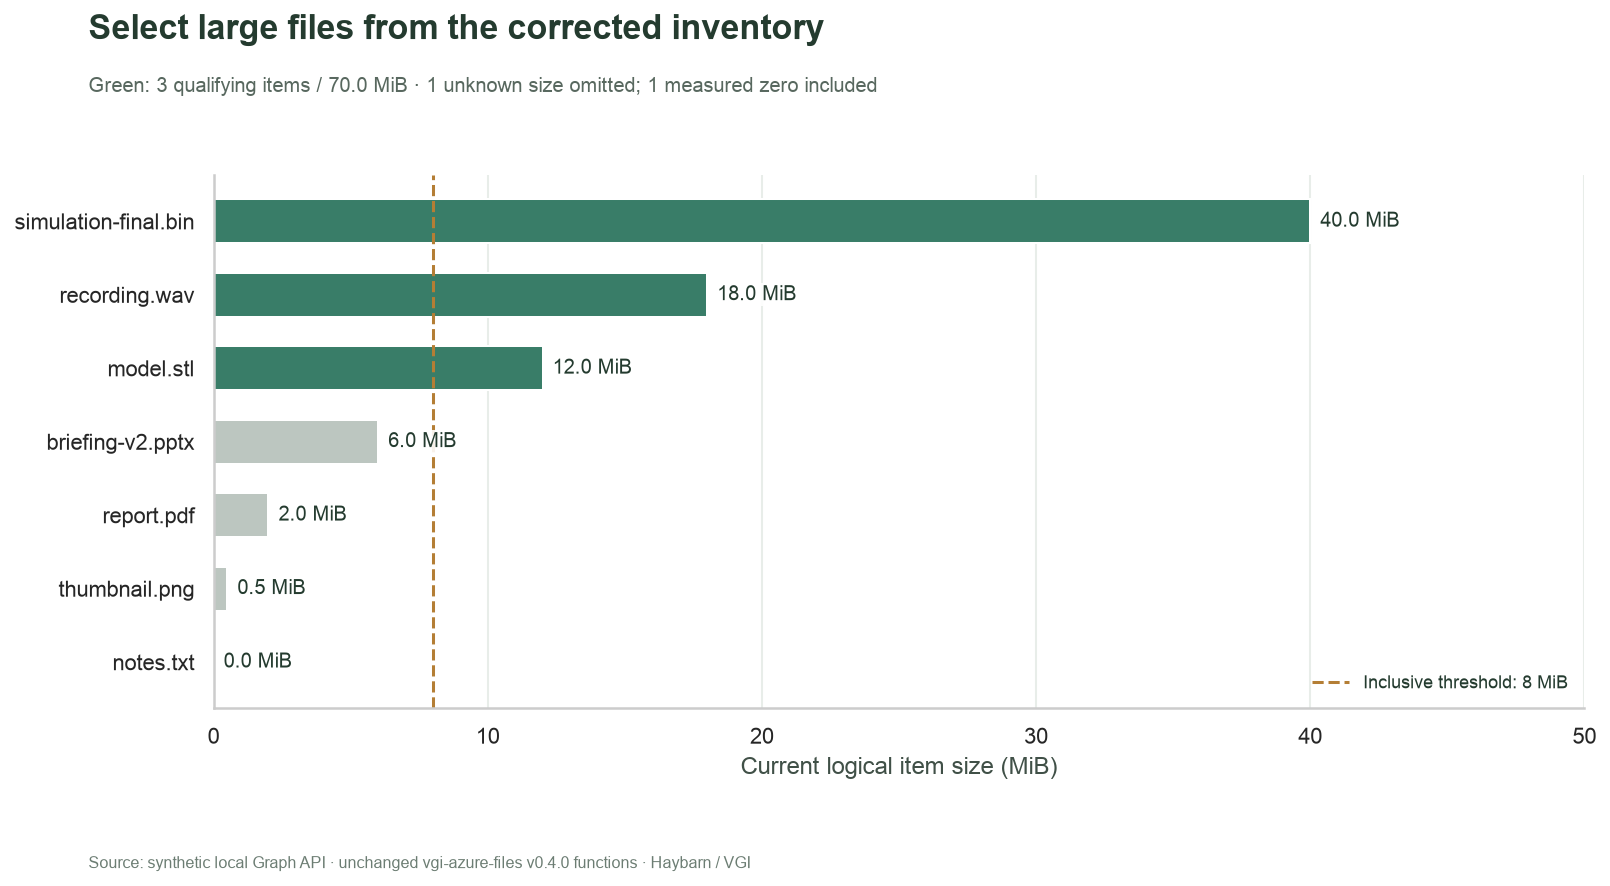

In [21]:
fig, ax = plt.subplots(figsize=(11.5, 6.2))
colors = ["#397D68" if selected else "#BCC6C0" for selected in current_sizes.selected]
bars = ax.barh(current_sizes.name, current_sizes.size_mib, color=colors, height=0.6)
ax.bar_label(
    bars,
    labels=[f"{v:.1f} MiB" for v in current_sizes.size_mib],
    padding=5,
    fontsize=10,
    bbox={"facecolor": "white", "edgecolor": "none", "pad": 1, "alpha": 0.9},
)
ax.axvline(
    LARGE_FILE_MIB,
    color="#B47E35",
    linestyle="--",
    linewidth=1.5,
    label=f"Inclusive threshold: {LARGE_FILE_MIB} MiB",
)
ax.set_xlim(0, max(float(current_sizes.size_mib.max()), LARGE_FILE_MIB) * 1.25)
ax.invert_yaxis()
ax.set_xlabel("Current logical item size (MiB)")
ax.grid(axis="y", visible=False)
ax.legend(fontsize=9, loc="lower right")
chart(
    fig,
    "Select large files from the corrected inventory",
    f"Green: {int(s.selected_items)} qualifying items / {s.selected_mib:.1f} MiB · "
    f"{int(a.unknown_sizes)} unknown size omitted; {int(a.measured_zero_sizes)} measured zero included",
)

## Validate the inventory and cursor

Exact BIGINT byte counts need no floating tolerance. Compare all stored fields
with the fresh full scan, preserve NULLs, and verify that removed IDs disappeared.
Only the chart's MiB conversion and percentage display use floating arithmetic.

In [22]:
%%sql checks <<
SELECT 'initial scan has one final marker' AS check_name,
       count(*) = 1 AS passed FROM initial_batch WHERE _row_kind = 'marker'
UNION ALL SELECT 'delta marker has no business fields', bool_and(
       id IS NULL AND name IS NULL AND size IS NULL AND change_type IS NULL)
       FROM changes_batch WHERE _row_kind = 'marker'
UNION ALL SELECT 'download capability column absent by default', NOT EXISTS (
       SELECT 1 FROM duckdb_columns() WHERE table_name = 'initial_batch' AND column_name = '_download_url')
UNION ALL SELECT 'inventory key unique', count(*) = count(DISTINCT (drive_id,id)) FROM inventory
UNION ALL SELECT 'removed IDs absent', NOT EXISTS (
       SELECT 1 FROM inventory i JOIN changes_batch c USING(id)
       WHERE i.drive_id = 'notebook-drive' AND c.change_type = 'removed')
UNION ALL SELECT 'inventory equals fresh full snapshot', NOT EXISTS (
       (SELECT * FROM inventory EXCEPT SELECT * FROM fresh_inventory)
       UNION ALL (SELECT * FROM fresh_inventory EXCEPT SELECT * FROM inventory))
UNION ALL SELECT 'cursor advanced for this drive',
       (SELECT delta_next FROM sync_state WHERE drive_id = 'notebook-drive') =
       (SELECT _delta_next FROM changes_batch WHERE _row_kind = 'marker');


In [23]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), "An inventory relationship failed"
assert any("$deltatoken=synthetic-v1&opaque=keep%2Bexact" in path for path in fixture.requests)
prose(
    f"**All {len(checks)} SQL relationships passed.** The real function made "
    f"**{len(fixture.requests)} local metadata GETs** across three materialized scans. "
    "The synthetic deltaLink was replayed verbatim; no content download endpoint was called."
)

,check_name,passed
0,initial scan has one final marker,True
1,delta marker has no business fields,True
2,download capability column absent by default,True
3,inventory key unique,True
4,removed IDs absent,True
5,inventory equals fresh full snapshot,True
6,cursor advanced for this drive,True


**All 7 SQL relationships passed.** The real function made **8 local metadata GETs** across three materialized scans. The synthetic deltaLink was replayed verbatim; no content download endpoint was called.

## Experiment: raise the threshold without rebuilding history

Change **`LARGE_FILE_MIB = 8` to `LARGE_FILE_MIB = 16`**, restart, and run all.
Predict fewer qualifying items and a smaller selected-byte total. Compare the
second figure's green bars and selected share. The first figure, corrected
inventory, missing-size coverage and cursor checks should remain unchanged.

This is sensitivity to an inclusive size threshold, not a content or retention
assessment. Unknown-size items remain unclassified at either setting. Restore
**8** for the default; the [guide](README.md) gives the separate experiment command.

In [24]:
con.close()
fixture_secret_directory.cleanup()
cleanup(fixture, previous_url)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)